# Ionosphere Radar Return Classification

A radar in Goose Bay, Labrador bounced signals off the ionosphere. Returns showing structure ('good', **g**) mean free electrons are organised up there; structureless returns ('bad', **b**) passed straight through. Each return is 17 pulse pairs reduced to 34 numbers (the second is constant zero, so it is dropped). Classify the return.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

raw = download('https://archive.ics.uci.edu/static/public/52/ionosphere.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
df = pd.read_csv(io.BytesIO(zf.read(name)), header=None)
print(df.shape)
df.head(3)

(351, 35)


,0,1,2,3,4,5,6,7,8,9,...,25,26,27,28,29,30,31,32,33,34
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g


In [2]:
y = df.iloc[:, -1]
X = df.iloc[:, :-1].drop(columns=[1])  # second attribute is constant 0 for every row
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.9318
Logistic Regression accuracy: 0.8977
              precision    recall  f1-score   support

           b       0.93      0.88      0.90        32
           g       0.93      0.96      0.95        56

    accuracy                           0.93        88
   macro avg       0.93      0.92      0.93        88
weighted avg       0.93      0.93      0.93        88



3     0.124019
5     0.112824
25    0.086198
1     0.080505
4     0.045080
26    0.044673
6     0.038799
0     0.036195
2     0.034353
22    0.032237
dtype: float64


<Axes: title={'center': 'Most informative radar attributes'}>

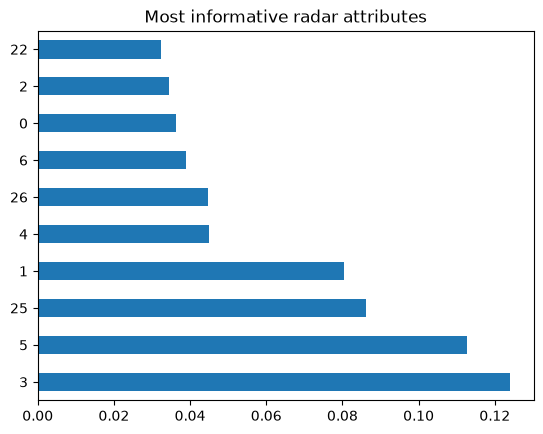

In [3]:
imp = pd.Series(rf.feature_importances_).sort_values(ascending=False)
print(imp.head(10))
imp.head(10).plot(kind='barh', title='Most informative radar attributes')